In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from criteo_incrementality.db import run_sql_file

balance = run_sql_file("03_balance.sql")
sanity = run_sql_file("02_sanity_checks.sql")
balance

Matplotlib is building the font cache; this may take a moment.


,feature,mean_t,mean_c,var_t,var_c,smd
0,f0,19.614755,19.651705,28.896686,29.031749,-0.006866
1,f1,10.070337,10.067935,0.011383,0.008647,0.023994
2,f2,8.446302,8.448173,0.089446,0.090406,-0.006241
3,f3,4.169412,4.232821,1.829073,1.542635,-0.048836
4,f4,10.339245,10.336526,0.118416,0.114705,0.007966
5,f5,4.026602,4.039339,0.191008,0.156450,-0.030557
6,f6,-4.182792,-3.999880,21.168646,19.731228,-0.040448
7,f7,5.105555,5.080284,1.470063,1.353249,0.021270
8,f8,3.933392,3.934652,0.003234,0.003074,-0.022433
9,f9,16.052589,15.886253,49.790673,46.269411,0.024001


In [4]:
n_c = sanity.loc[sanity.treatment == 0, "n_users"].item()
n_t = sanity.loc[sanity.treatment == 0, "n_users"].item()
se = np.sqrt(1/n_t + 1/n_c)
band = 1.96 * se
print(f"SE = {se:.5f}, 95% noise band = ±{band:.4f}")

SE = 0.00098, 95% noise band = ±0.0019


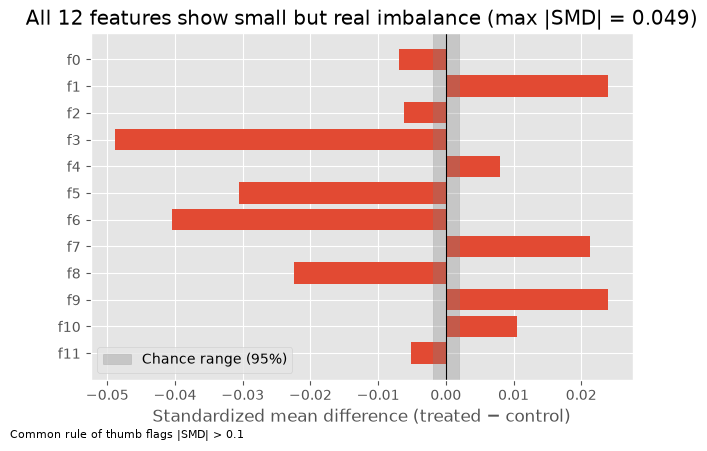

In [ ]:
plt.style.use('ggplot')

fig, ax = plt.subplots(figsize=(7, 4.5))          

ax.barh(balance["feature"], balance["smd"])      
ax.invert_yaxis()                                

ax.axvline(0, color="black", linewidth=0.8)       
ax.axvspan(-band, band, color="gray", alpha=0.3,  
           label="Chance range (95%)")            

ax.set_xlabel("Standardized mean difference (treated − control)")
ax.set_title("All 12 features show small but real imbalance (max |SMD| = 0.049)")
ax.legend(loc="lower left")                       
fig.text(0.01, -0.02, "Common rule of thumb flags |SMD| > 0.1", fontsize=8)  # note below the chart

fig.savefig("../reports/balance.png", dpi=200, bbox_inches="tight")